In [ ]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.manifold import TSNE
import umap
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw12_ont25_2022.parquet")

In [ ]:
feature_columns = [col for col in df.columns if col.startswith("feature_")]
if len(feature_columns) == 0:
    raise ValueError("No feature_* columns found.")

print(f"Number of features: {len(feature_columns)}")

X = df[feature_columns].to_numpy(dtype="float64")

In [ ]:
#HDBSCAN for high-dimensional data
hdbscan = HDBSCAN(min_cluster_size=500, min_samples=1)

H = hdbscan.fit(X)
labels = H.labels_

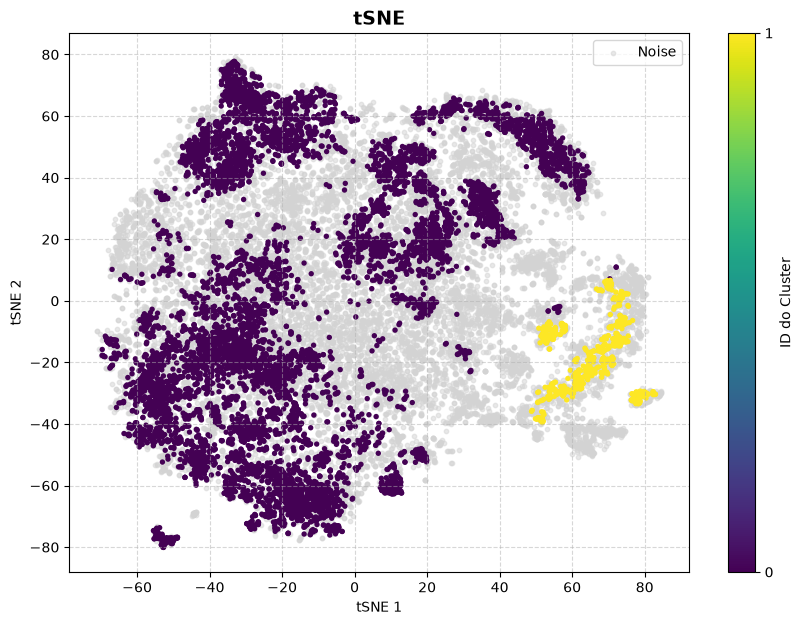

In [ ]:
#Plotting the results of HDBSCAN in 2D using tSNE and UMAP

tsne = TSNE(n_components=2, random_state=42)
tsne_results = tsne.fit_transform(X)

plt.figure(figsize=(10, 7))

noise_mask = labels == -1
clustered_mask = ~noise_mask
plt.scatter(tsne_results[noise_mask, 0],tsne_results[noise_mask, 1],c="lightgrey",label="Noise",alpha=0.5,s=10)
scatter = plt.scatter(tsne_results[clustered_mask, 0],tsne_results[clustered_mask, 1],c=labels[clustered_mask],cmap="viridis",s=15,edgecolors="none",)

plt.title("tSNE", fontsize=14, fontweight="bold")
plt.xlabel("tSNE 1")
plt.ylabel("tSNE 2")

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
if n_clusters > 0:
    cbar = plt.colorbar(scatter, ticks=np.unique(labels[clustered_mask]))
    cbar.set_label("ID Cluster")

plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


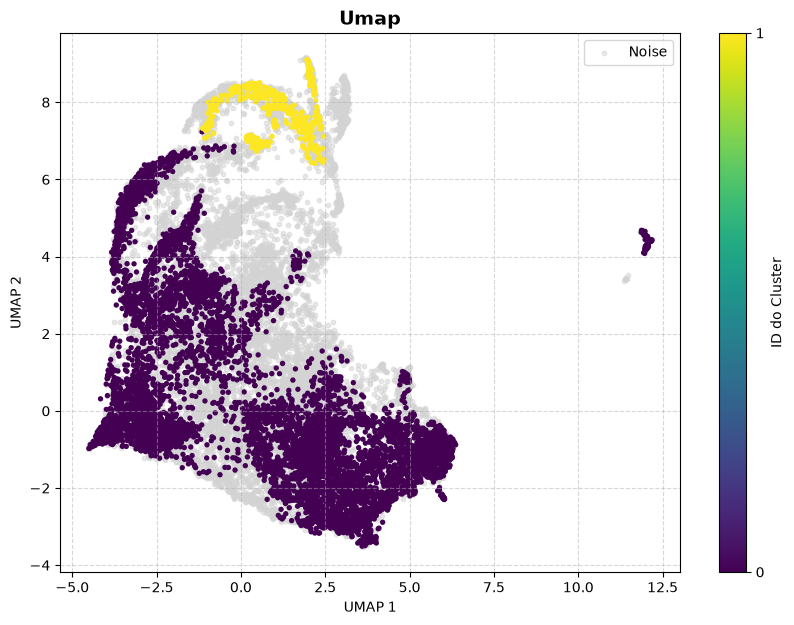

In [19]:
umap_model = umap.UMAP(n_components=2, random_state=42)
umap_results = umap_model.fit_transform(X)

plt.figure(figsize=(10, 7))

noise_mask = labels == -1
clustered_mask = ~noise_mask
plt.scatter(umap_results[noise_mask, 0],umap_results[noise_mask, 1],c="lightgrey",label="Noise",alpha=0.5,s=10)
scatter = plt.scatter(umap_results[clustered_mask, 0],umap_results[clustered_mask, 1],c=labels[clustered_mask],cmap="viridis",s=15,edgecolors="none",)

plt.title("Umap", fontsize=14, fontweight="bold")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
if n_clusters > 0:
    cbar = plt.colorbar(scatter, ticks=np.unique(labels[clustered_mask]))
    cbar.set_label("ID Cluster")

plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()